# Figures 17–18 — 3-regular graphs on the (noisy) H2-1 emulator

Standalone QAOA ($p=2, 4$; 1000 shots) vs qReduMIS powered by QAOA ($p=2$; 250 shots per QPU call) on random
3-regular graphs, compared with the noiseless statevector simulator.

- **Fig. 17** (`figures/3_regular_pmis_noisy_vs_noiseless_violin.png`): success probability $P_{\mathrm{MIS}}$,
  noisy emulator (solid) vs noiseless simulator (hatched).
- **Fig. 18** (`figures/quantum_calls_qredumis_3regular_boxplot_emu.png`): number of QPU calls made by qReduMIS
  on the emulator.

In [1]:
%matplotlib inline
import sys, os
_REL_ROOT = os.getcwd() if os.path.isdir("consolidated_results") else os.path.abspath(os.pardir)  # release root (re-run safe)
sys.path.insert(0, _REL_ROOT)  # release root (for utils/)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from utils.utils_db import make_df_from_db, post_process_qredumis
from utils.derived import DerivedData as _DerivedData

# Flat benchmark JSONs under data/data_3regular/results* were consolidated into
# consolidated_results/flat_json.csv; _D.json_frame(path) returns what pd.read_json(path) used to.
_D = _DerivedData()

BASE = _REL_ROOT  # release root
os.chdir(BASE)  # resolve relative paths from the release root

SAVE_FIGURES = False  # set False to skip saving figures
os.makedirs("figures", exist_ok=True)


## Load results

In [2]:
## Noisy emulator -- standalone QAOA (p = 2, 4)
file='data/data_3regular/results_emulator_qaoa_db_17Sep/benchmark_qaoa_3regular_graphs.db'
df_qaoa_1 = make_df_from_db(file)
file='data/data_3regular/results_emulator_qaoa_db_17Sep/benchmark_qaoa_3regular_graphs_more.db'
df_qaoa_2 = make_df_from_db(file)

df_qaoa = pd.concat([df_qaoa_1, df_qaoa_2], axis=0)


In [3]:
## Noisy emulator -- qReduMIS powered by QAOA p = 2 (one P_MIS per instance)
p=2
file='data/data_3regular/results_emulator_qredumis_db_new_17Sep/benchmark_qredumis_3regular_graphs.db'
df_qredumis_1 = make_df_from_db(file)
df_qredumis_1 = post_process_qredumis(df_qredumis_1[df_qredumis_1['p']==p], df_qaoa_1[df_qaoa_1['p']==p])
file='data/data_3regular/results_emulator_qredumis_db_new_17Sep/benchmark_qredumis_3regular_graphs_more.db'
df_qredumis_2 = make_df_from_db(file)
df_qredumis_2 = post_process_qredumis(df_qredumis_2[(df_qredumis_2['seed']<7) & (df_qredumis_2['N']==24)], df_qaoa_2)

df_qredumis = pd.concat([df_qredumis_1, df_qredumis_2], axis=0)

In [4]:
## Noiseless statevector simulator -- QAOA (p = 2, 4) and qReduMIS (p = 2)
def _post_process_qredumis_noiseless(df: pd.DataFrame) -> pd.DataFrame:
    """One ``pmis`` value per (N, seed) for noiseless qReduMIS JSON files.

    ``pmis`` = fraction of classical shots whose MIS matched the baseline.
    """
    rows = []
    for N in sorted(df['N'].unique()):
        for seed in sorted(df.loc[df['N'] == N, 'seed'].unique()):
            sub = df[(df['N'] == N) & (df['seed'] == seed)]
            cshots = len(sub)
            if cshots == 0:
                continue
            hits = sub.apply(
                lambda r: r['baseline'] == len(r['atom positions MIS']), axis=1
            ).sum()
            rows.append({'N': N, 'seed': seed, 'pmis': hits / cshots})
    return pd.DataFrame(rows)


# ─── load the noiseless results ────────────────────────────────────────────
_DAYS = [11, 12, 13, 14, 15]
_BASE_NL = 'data/data_3regular/results'

df_qaoa_noiseless: dict[int, pd.DataFrame] = {}
for _p in [2, 4]:
    _parts = []
    for _day in _DAYS:
        _f = f'{_BASE_NL}/benchmark_qaoa_3regular_graphs_2025-09-{_day}_p{_p}.json'
        if _D.json_available(_f):
            _parts.append(_D.json_frame(_f))
    df_qaoa_noiseless[_p] = (
        pd.concat(_parts, ignore_index=True) if _parts else pd.DataFrame()
    )

_p = 2
_parts = []
for _day in _DAYS:
    _f = f'{_BASE_NL}/benchmark_qredumis_3regular_graphs_2025-09-{_day}_p{_p}.json'
    if _D.json_available(_f):
        _parts.append(_D.json_frame(_f))
df_qredumis_noiseless_raw = (
    pd.concat(_parts, ignore_index=True) if _parts else pd.DataFrame()
)
df_qredumis_noiseless = (
    _post_process_qredumis_noiseless(df_qredumis_noiseless_raw)
    if not df_qredumis_noiseless_raw.empty
    else pd.DataFrame(columns=['N', 'seed', 'pmis'])
)

print('noiseless QAOA   rows:',
      {p: len(df_qaoa_noiseless[p]) for p in df_qaoa_noiseless})
print('noiseless qReduMIS rows (post-processed):', len(df_qredumis_noiseless))


noiseless QAOA   rows: {2: 186, 4: 185}
noiseless qReduMIS rows (post-processed): 178


## Fig. 17 — success probability, noisy vs noiseless

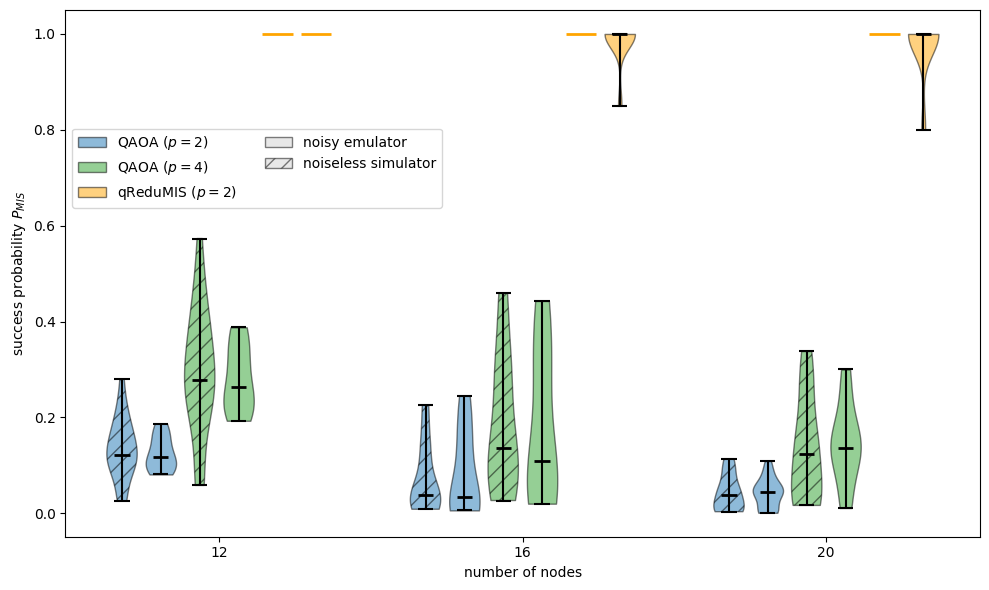

In [5]:
## Fig. 17 -- P_MIS, noisy emulator (solid) vs noiseless simulator (hatched)

default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
colors = {2: default_colors[0], 4: default_colors[2]}
qredu_color = 'orange'

Ns = [N for N in sorted(df_qredumis['N'].unique()) if N <= 20]
N_to_i = {N: i for i, N in enumerate(Ns)}
WIDTH = 0.10

# Within each N group, six slots ordered left → right as:
#   1. QAOA p=2  noiseless
#   2. QAOA p=2  noisy
#   3. QAOA p=4  noiseless
#   4. QAOA p=4  noisy
#   5. qReduMIS  noiseless
#   6. qReduMIS  noisy
_GROUP_OFFSETS = np.linspace(-0.32, 0.32, 6)


def _draw_violin(ax, data, pos, face, hatch=None):
    """Draw a single coloured (optionally hatched) violin at ``pos``."""
    arr = np.asarray(data, dtype=float)
    arr = arr[~np.isnan(arr)]
    # violinplot needs >=2 distinct samples for a kernel estimate.
    if arr.size < 2 or np.allclose(arr, arr[0]):
        # Fall back to a short horizontal tick so the slot is not empty.
        if arr.size >= 1:
            ax.hlines(arr.mean(), pos - WIDTH / 2, pos + WIDTH / 2,
                      colors=face, linewidth=2)
        return
    parts = ax.violinplot(
        arr, positions=[pos], widths=WIDTH,
        showmeans=False, showmedians=True, showextrema=True,
    )
    for body in parts['bodies']:
        body.set_facecolor(face)
        body.set_edgecolor('black')
        body.set_alpha(0.5)
        if hatch is not None:
            body.set_hatch(hatch)
    for key in ('cbars', 'cmins', 'cmaxes', 'cmedians'):
        if key in parts:
            parts[key].set_color('black')
            if key == 'cmedians':
                parts[key].set_linewidth(2)


fig, ax = plt.subplots(figsize=(10, 6))
for N in Ns:
    i = N_to_i[N]

    # QAOA p=2 / p=4 — noiseless then noisy
    for idx, p in enumerate([2, 4]):
        df_nl = df_qaoa_noiseless.get(p, pd.DataFrame())
        if not df_nl.empty:
            _draw_violin(
                ax, df_nl[df_nl['N'] == N]['pmis'],
                i + _GROUP_OFFSETS[2 * idx], colors[p], hatch='//',
            )
        _draw_violin(
            ax, df_qaoa[(df_qaoa['p'] == p) & (df_qaoa['N'] == N)]['pmis'],
            i + _GROUP_OFFSETS[2 * idx + 1], colors[p],
        )

    # qReduMIS p=2 — noiseless then noisy
    if not df_qredumis_noiseless.empty:
        _draw_violin(
            ax,
            df_qredumis_noiseless[df_qredumis_noiseless['N'] == N]['pmis'],
            i + _GROUP_OFFSETS[4], qredu_color, hatch='//',
        )
    _draw_violin(
        ax, df_qredumis[df_qredumis['N'] == N]['pmis'],
        i + _GROUP_OFFSETS[5], qredu_color,
    )

ax.set_xlabel('number of nodes')
ax.set_ylabel(r'success probability $P_{MIS}$')
ax.set_xticks(range(len(Ns)))
ax.set_xticklabels(Ns)

method_handles = [
    mpatches.Patch(facecolor=colors[2],  alpha=0.5, edgecolor='black', label='QAOA ($p=2$)'),
    mpatches.Patch(facecolor=colors[4],  alpha=0.5, edgecolor='black', label='QAOA ($p=4$)'),
    mpatches.Patch(facecolor=qredu_color, alpha=0.5, edgecolor='black', label='qReduMIS ($p=2$)'),
]
style_handles = [
    mpatches.Patch(facecolor='lightgray', alpha=0.5, edgecolor='black',
                   label='noisy emulator'),
    mpatches.Patch(facecolor='lightgray', alpha=0.5, edgecolor='black', hatch='//',
                   label='noiseless simulator'),
]
ax.legend(handles=method_handles + style_handles, loc='center left', bbox_to_anchor=(0.0, 0.7), ncol=2)
fig.tight_layout()
if SAVE_FIGURES:
    fig.savefig(
        'figures/3_regular_pmis_noisy_vs_noiseless_violin.png',
        dpi=300, bbox_inches='tight',
    )
plt.show()


## Fig. 18 — QPU calls made by qReduMIS

In [6]:
## qReduMIS raw records (one row per classical shot), for the QPU-call counts
file='data/data_3regular/results_emulator_qredumis_db_new_17Sep/benchmark_qredumis_3regular_graphs.db'
df_qredumis_1 = make_df_from_db(file)
file='data/data_3regular/results_emulator_qredumis_db_new_17Sep/benchmark_qredumis_3regular_graphs_more.db'
df_qredumis_2 = make_df_from_db(file)

df_qredumis_raw = pd.concat([df_qredumis_1, df_qredumis_2], axis=0)


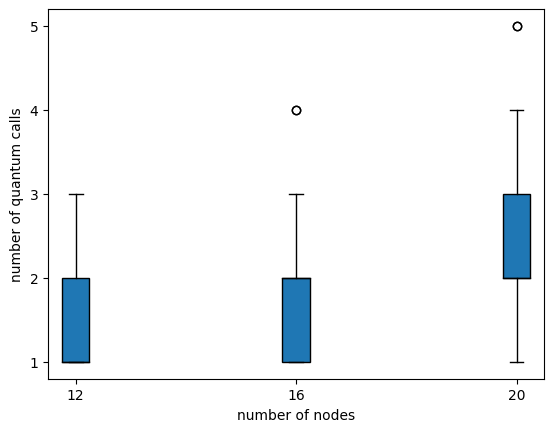

In [7]:
## Fig. 18 -- number of QPU calls made by qReduMIS (p = 2) on the emulator
# Prepare data for box plot: group 'num iteration' by 'N'
sub_df = df_qredumis_raw[df_qredumis_raw['p']==2]
data_to_plot = [sub_df[sub_df['N'] == n]['num iteration'] for n in [12,16,20]]

fig, ax = plt.subplots()
positions = [12, 16, 20]
bp = ax.boxplot(data_to_plot, patch_artist=True, positions=positions)
ax.set_xlabel('number of nodes')
ax.set_ylabel('number of quantum calls')

pastel_blue = '#1f77b4'
for box in bp['boxes']:
    box.set_facecolor(pastel_blue)
    box.set_edgecolor('black')
for whisker in bp['whiskers']:
    whisker.set_color('black')
for cap in bp['caps']:
    cap.set_color('black')
for median in bp['medians']:
    median.set_color('black')
if 'means' in bp:
    for mean in bp['means']:
        mean.set_color('black')
        
ax.set_yticks([1,2,3,4,5])
ax.set_xticks([12,16,20])

if SAVE_FIGURES:
    plt.savefig("figures/quantum_calls_qredumis_3regular_boxplot_emu.png", format='png', dpi=300)
plt.show()

In [8]:
## Numbers quoted in the text: QPU calls per classical shot
calls = sub_df[sub_df['N'].isin(positions)]['num iteration']
for n, d in zip(positions, data_to_plot):
    print(f"N={n}: mean QPU calls = {d.mean():.2f}, max = {d.max()}")
print(f"Fraction of runs with <= 4 QPU calls: {(calls <= 4).mean():.3f}  "
      f"(<= {4 * 250} shots at 250 shots per call)")


N=12: mean QPU calls = 1.38, max = 3
N=16: mean QPU calls = 1.76, max = 4
N=20: mean QPU calls = 2.37, max = 5
Fraction of runs with <= 4 QPU calls: 0.997  (<= 1000 shots at 250 shots per call)
